# Colab 15 KI Labor als Gruppenspiel

**50 Minuten insgesamt · Gruppen mit 3 bis 4 Personen · Eine Dokumentation pro Gruppe**

Ihr prüft eine KI, die Kleidungsbilder erkennt. Eure vier Spielrunden heissen **Störfall-Challenge**, **Geheime Kleidungsbilder**, **Trainingsjury** und **Mythenjagd**. Euer Ziel ist es, gemeinsam alle vier Spielrunden abzuschliessen.: Für jedes Zeichen braucht ihr eine Beobachtung und eine kritische Prüfung. Eine widerlegte Vermutung oder eine niedrige Trefferquote darf ein gutes Forschungsergebnis sein.

Öffnet **Colab_15_Spielauftrag.pdf** und gemeinsam **Colab_15_Labordokumentation.docx**. Nutzt ein laufendes Colab pro Gruppe. Ihr braucht keine Datei aus Colab 14.

Verteilt die Rollen **Bedienung**, **Beobachtung**, **kritische Prüfung** und **Dokumentation**. Zu dritt werden Beobachtung und Dokumentation verbunden. Wechselt nach jeder Spielrunde im Uhrzeigersinn. Die Person mit der Rolle «Kritische Prüfung» hakt die Runde ab, wenn ihr eure Beobachtung belegt und erklärt habt, was das Ergebnis nicht beweist.

| Zeit | Eure Aufgabe |
|---|---|
| 0–5 Minuten | Team bilden und Start A bis C vorbereiten |
| 5–12 Minuten | E1 Grundmodell trainieren und Gewichte ansehen |
| 12–20 Minuten | Runde 1 mit E2 Störfall-Challenge |
| 20–32 Minuten | Runde 2 mit E3 Geheime Kleidungsbilder |
| 32–38 Minuten | Runde 3 mit E4 Drehvarianten beurteilen |
| 38–46 Minuten | Runde 3 mit E5 Trainingsjury abschliessen |
| 46–50 Minuten | Runde 4 Mythenjagd, prüfen und abgeben |

**Wichtig:** Führt die Zellen einzeln der Reihe nach aus. Nutzt nicht «Alle ausführen», denn bei der Bildsuche kommt eure Vermutung vor der Auflösung.

Wenn ihr wegen Login, Download oder langer Rechnung nicht weiterkommt, bearbeitet die **betroffene Spielrunde vollständig mit Colab_15_Ersatzdaten.pdf**. Andere Runden dürft ihr weiterhin mit dem Colab bearbeiten. Nutzt innerhalb einer Runde nur eine Datenquelle. Bei gemischter Bearbeitung markiert ihr das in der Labordokumentation und nennt die Rundennummern mit Ersatzkarten. Reserviert die letzten vier Minuten für Mythenjagd und Abgabe.

## Start A bis C bis Minute 5

1. Öffnet dieses Notebook in Google Colab.
2. Wählt unter **Laufzeit → Laufzeittyp ändern** eine GPU, zum Beispiel T4, falls angeboten. Ohne freie GPU geht es auf der CPU weiter.
3. Führt Start A, Start B und Start C nacheinander aus. Die Ausgabe von Start A zeigt das tatsächlich aktive Gerät.

Eine GPU kann viele Rechnungen gleichzeitig ausführen. Sie garantiert keine besseren Vorhersagen. Beim Wechsel des Laufzeittyps startet die Umgebung neu. Führt dann wieder alle Startzellen aus.

**Technische Hilfe:** Bei Downloadfehler Start B einmal erneut versuchen. Kommt ihr länger als drei Minuten nicht weiter oder ist die Zeit einer Phase abgelaufen, bearbeitet die betroffene Spielrunde vollständig mit den Ersatzkarten. Innerhalb dieser Runde verwendet ihr nur eine Quelle; gemischte Bearbeitung und Rundennummern kennzeichnet ihr in der Labordokumentation.

Ist nach E1 kein trainiertes Grundmodell verfügbar, nutzt für die späteren rechenabhängigen Versuche E2, E3 und E5 die Ersatzkarten und überspringt diese Rechenzellen. Fehlen auch die Bilddaten für E4, nutzt ihr dafür ebenfalls die Karten. Die vier Spiele könnt ihr so trotzdem bearbeiten. Ihr müsst fehlende Zellen nicht erzwingen oder frühere Runden neu beginnen.

In [1]:
#@title Start A – Rechengerät prüfen { display-mode: "form" }
import copy
import math
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn, optim
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as vision_functional
from IPython.display import display


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

class_names = [
    "T-Shirt/Oberteil", "Hose", "Pullover", "Kleid", "Mantel",
    "Sandale", "Hemd", "Turnschuh", "Tasche", "Stiefelette",
]
batch_size = 64
training_epochs = 2
learning_rate = 0.001
lesson_state = {}
diagnostic_dir = None

def report_device():
    print("PyTorch:", torch.__version__)
    if device.type == "cuda":
        print("GPU aktiv:", torch.cuda.get_device_name(0))
    else:
        print("CPU aktiv. Keine CUDA-GPU verfügbar; alle Versuche funktionieren trotzdem.")
    probe = torch.tensor([2.0, 3.0], device=device)
    print("Gerät der Proberechnung:", probe.device)
    print("Proberechnung 2 + 3 =", probe.sum().item())
    return str(device)

active_device = report_device()

PyTorch: 2.14.1+cu130
GPU aktiv: Tesla T4
Gerät der Proberechnung: cuda:0
Proberechnung 2 + 3 = 5.0


### Die Bildmengen und der faire Übungsstapel

Training verändert Gewichte und Grundwerte. Getrennte **Validierungsbilder** helfen zu prüfen, ob das Gelernte auch zu anderen Bildern passt.

Wir verwenden **6'000 verschiedene Trainingsoriginale** und **2'000 getrennte Validierungsbilder**. Jedes Trainingsoriginal erhält drei Übungsplätze:

| Modell | Platz 1 | Platz 2 | Platz 3 |
|---|---|---|---|
| Kontrollmodell | Original | dasselbe Original | dasselbe Original |
| Drehmodell in E5 | Original | −10° | +10° |

Beide Modelle sehen **18'000 Vorlagen je Epoche** und trainieren **zwei Epochen**. Eine Epoche ist ein vollständiger Durchgang durch den Übungsstapel. Das sind je **36'000 Bildpräsentationen**. Nur die Ansichten unterscheiden sich.

Die Kopien sind keine unabhängig neu fotografierten Kleidungsstücke. Die übrigen 52'000 Trainingsbilder bleiben unbenutzt. Der offizielle Testbestand wird hier nicht ausgewertet.

In [2]:
#@title Start B – Getrennte Bildmengen und Kontrollstapel vorbereiten { display-mode: "form" }
def setup_data():
    data_root = Path("fashion_mnist_data")
    secure_mirror = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
    if secure_mirror not in datasets.FashionMNIST.mirrors:
        datasets.FashionMNIST.mirrors = [secure_mirror] + datasets.FashionMNIST.mirrors
    full_dataset = datasets.FashionMNIST(
        root=str(data_root), train=True, download=True,
        transform=transforms.ToTensor(),
    )
    train_subset, validation_subset, unused_subset = random_split(
        full_dataset, [6000, 2000, 52000],
        generator=torch.Generator().manual_seed(42),
    )
    train_indices = torch.tensor(train_subset.indices)
    validation_indices = torch.tensor(validation_subset.indices)
    assert not set(train_subset.indices).intersection(validation_subset.indices)
    train_images = full_dataset.data[train_indices].unsqueeze(1).float().div(255.0)
    train_labels = full_dataset.targets[train_indices].long()
    validation_images = full_dataset.data[validation_indices].unsqueeze(1).float().div(255.0)
    validation_labels = full_dataset.targets[validation_indices].long()
    repeated_labels = train_labels.repeat_interleave(3)
    control_dataset = TensorDataset(train_images.repeat_interleave(3, dim=0), repeated_labels)
    lesson_state.clear()
    lesson_state.update({
        "train_images": train_images, "train_labels": train_labels,
        "validation_images": validation_images, "validation_labels": validation_labels,
        "validation_dataset": TensorDataset(validation_images, validation_labels),
        "control_dataset": control_dataset,
        "train_indices": train_subset.indices,
        "validation_indices": validation_subset.indices,
    })
    print("\nTraining: 6'000 Originalbilder; Validierung: 2'000 andere Bilder.")
    print("Jedes Trainingsoriginal erhält drei Vorlagenplätze: insgesamt 18'000.")
    print("Beim Grundmodell stehen auf allen drei Plätzen dieselben Originalbilder.")
    print("Beide Vergleichsnetze trainieren zwei Epochen: je 36'000 Bildpräsentationen.")
    print("Die übrigen 52'000 Trainingsbilder bleiben unbenutzt. Kein Testbestand wird ausgewertet.")
    display(pd.DataFrame({"Klasse": range(10), "Kleidungsstück": class_names}))
    return lesson_state

setup_data()
print("Bildmengen vorbereitet. Weiter mit Start C.")

100%|██████████| 26.4M/26.4M [00:00<00:00, 500MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 32.5MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 306MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.6MB/s]



Training: 6'000 Originalbilder; Validierung: 2'000 andere Bilder.
Jedes Trainingsoriginal erhält drei Vorlagenplätze: insgesamt 18'000.
Beim Grundmodell stehen auf allen drei Plätzen dieselben Originalbilder.
Beide Vergleichsnetze trainieren zwei Epochen: je 36'000 Bildpräsentationen.
Die übrigen 52'000 Trainingsbilder bleiben unbenutzt. Kein Testbestand wird ausgewertet.


,Klasse,Kleidungsstück
0,0,T-Shirt/Oberteil
1,1,Hose
2,2,Pullover
3,3,Kleid
4,4,Mantel
5,5,Sandale
6,6,Hemd
7,7,Turnschuh
8,8,Tasche
9,9,Stiefelette


Bildmengen vorbereitet. Weiter mit Start C.


In [3]:
#@title Start C – Modell und vorbereitete Hilfsfunktionen { display-mode: "form" }
def save_figure(name):
    if diagnostic_dir is not None:
        target = Path(diagnostic_dir)
        target.mkdir(parents=True, exist_ok=True)
        plt.gcf().savefig(target / name, dpi=150, bbox_inches="tight")


def set_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True


def snapshot(model):
    return {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}


def state_matches(model, saved):
    return all(torch.equal(value.detach().cpu(), saved[name])
               for name, value in model.state_dict().items())


class FashionMNISTModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
            nn.LogSoftmax(dim=1),
        )

    def forward(self, images):
        pixels = self.flatten(images)
        return self.linear_relu_stack(pixels)


def make_loader(dataset, shuffle=False, seed=7):
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle,
        generator=torch.Generator().manual_seed(seed),
        num_workers=0, pin_memory=(device.type == "cuda"),
    )


def evaluate(model, dataset):
    model.eval()
    loss_function = nn.NLLLoss()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in make_loader(dataset):
            images = images.to(device, non_blocking=(device.type == "cuda"))
            labels = labels.to(device, non_blocking=(device.type == "cuda"))
            log_probabilities = model(images)
            loss = loss_function(log_probabilities, labels)
            loss_sum += loss.item() * labels.numel()
            correct += (log_probabilities.argmax(dim=1) == labels).sum().item()
            total += labels.numel()
    return {"loss": loss_sum / total, "accuracy": 100.0 * correct / total,
            "correct": int(correct), "total": int(total)}


def rotate_images(images, angle):
    # Die Vorverarbeitung bleibt auf der CPU. 28 x 28 bleibt erhalten;
    # trotzdem können Teile am Rand abgeschnitten werden.
    images = images.detach().cpu()
    if angle == 0:
        return images.clone()
    chunks = []
    for chunk in images.split(256):
        chunks.append(vision_functional.rotate(
            chunk, float(angle), interpolation=InterpolationMode.BILINEAR,
            expand=False, fill=0.0,
        ))
    return torch.cat(chunks, dim=0).clamp(0.0, 1.0)


def train_model(dataset, name, seed=7):
    set_seed(seed)
    model = FashionMNISTModel().to(device)
    initial_state = snapshot(model)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    loss_function = nn.NLLLoss()
    train_loader = make_loader(dataset, shuffle=True, seed=seed)
    history = []
    updates = 0
    presentations = 0
    if device.type == "cuda":
        torch.cuda.synchronize()
    started = time.perf_counter()
    print(f"{name}: 128 versteckte Neuronen, Lernrate {learning_rate:g}, {training_epochs} Epochen")
    print("Gerät des Modells:", next(model.parameters()).device)
    for epoch in range(1, training_epochs + 1):
        model.train()
        for images, labels in train_loader:
            images = images.to(device, non_blocking=(device.type == "cuda"))
            labels = labels.to(device, non_blocking=(device.type == "cuda"))
            optimizer.zero_grad()
            log_probabilities = model(images)
            loss = loss_function(log_probabilities, labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Der Trainings-Loss ist nicht endlich.")
            loss.backward()
            optimizer.step()
            updates += 1
            presentations += labels.numel()
        metrics = evaluate(model, lesson_state["validation_dataset"])
        history.append({"epoch": epoch, **metrics})
        print(f"Epoche {epoch}: Validierungs-Loss {metrics['loss']:.3f}; "
              f"Treffer Validierung {metrics['accuracy']:.2f} %")
    if device.type == "cuda":
        torch.cuda.synchronize()
    result = {"model": model, "initial_state": initial_state, "final_state": snapshot(model),
              "history": history, "updates": updates, "presentations": presentations,
              "seconds": time.perf_counter() - started,
              "parameter_count": sum(parameter.numel() for parameter in model.parameters())}
    assert result["parameter_count"] == 101770
    assert updates == 564 and presentations == 36000
    return result


def run_e1():
    if "control_dataset" not in lesson_state:
        raise RuntimeError("Führe zuerst setup_data() aus.")
    for key in ["mystery", "class_patterns", "selected_class_patterns", "damage_trials", "damage_table",
                "augmented", "comparison_table", "comparison_metrics"]:
        lesson_state.pop(key, None)
    result = train_model(lesson_state["control_dataset"], "Grundmodell ohne Drehung")
    lesson_state["baseline"] = result
    metrics = evaluate(result["model"], lesson_state["validation_dataset"])
    print("Parameter:", result["parameter_count"])
    print("Bildpräsentationen:", result["presentations"], "| Anpassungsschritte:", result["updates"])
    example_index = 0
    image = lesson_state["validation_images"][example_index:example_index + 1]
    actual_class = lesson_state["validation_labels"][example_index].item()
    with torch.no_grad():
        predicted_class = result["model"](image.to(device)).argmax(dim=1).item()
    fig, axes = plt.subplots(1, 3, figsize=(9.8, 3.2))
    axes[0].imshow(image[0, 0], cmap="gray", vmin=0, vmax=1)
    axes[0].set_title(f"Validierungsbild 0\nEcht: {actual_class} {class_names[actual_class]}\n"
                      f"Vorhersage: {predicted_class} {class_names[predicted_class]}", fontsize=9)
    weight_key = "linear_relu_stack.0.weight"
    before = result["initial_state"][weight_key][0].reshape(28, 28)
    after = result["final_state"][weight_key][0].reshape(28, 28)
    limit = max(before.abs().max().item(), after.abs().max().item())
    axes[1].imshow(before, cmap="coolwarm", vmin=-limit, vmax=limit)
    axes[1].set_title("Gewichte von Neuron 0\nvor dem Training", fontsize=9)
    axes[2].imshow(after, cmap="coolwarm", vmin=-limit, vmax=limit)
    axes[2].set_title("Dieselben 784 Gewichte\nnach dem Training", fontsize=9)
    for axis in axes:
        axis.axis("off")
    fig.suptitle("Bild ist Eingabe; Gewichtbilder sind Zahlenkarten, keine gespeicherten Kleiderbilder.", fontsize=10)
    fig.tight_layout()
    save_figure("e1_forward_and_weights.png")
    plt.show()
    summary = pd.DataFrame([{
        "Parameter": result["parameter_count"], "Loss Validierung": metrics["loss"],
        "Treffer Validierung %": metrics["accuracy"],
        "Echte Klasse Beispiel": actual_class, "Vorhergesagte Klasse Beispiel": predicted_class,
    }])
    display(summary.round(3))
    print("Gewichte und Bias-Werte tragen gemeinsam zum gelernten Verhalten bei.")
    print("Verstecktes Neuron 0 ist nicht die Ausgabeklasse 0.")
    print("Blau zeigt negative, Rot positive Gewichte; beide Zahlenkarten nutzen dieselbe Skala.")
    return summary


def damaged_model(model, fraction, seed):
    candidate = copy.deepcopy(model).to(device)
    weight_parameters = [candidate.linear_relu_stack[0].weight,
                         candidate.linear_relu_stack[2].weight]
    flat = torch.cat([weight.detach().cpu().flatten() for weight in weight_parameters])
    order = torch.randperm(flat.numel(), generator=torch.Generator().manual_seed(seed))
    selected_count = int(flat.numel() * fraction)
    flat[order[:selected_count]] = 0.0
    offset = 0
    with torch.no_grad():
        for weight in weight_parameters:
            count = weight.numel()
            weight.copy_(flat[offset:offset + count].reshape_as(weight).to(device))
            offset += count
    return candidate, selected_count


def run_e2():
    baseline = lesson_state["baseline"]
    before = snapshot(baseline["model"])
    before_flags = [parameter.requires_grad for parameter in baseline["model"].parameters()]
    rows, trials = [], []
    for percent in [0, 10, 30, 60]:
        accuracies = []
        for seed in [11, 22, 33]:
            candidate, count = damaged_model(baseline["model"], percent / 100.0, seed)
            metrics = evaluate(candidate, lesson_state["validation_dataset"])
            accuracies.append(metrics["accuracy"])
            trials.append({"percent": percent, "seed": seed, "selected_weights": count, **metrics})
        rows.append({"Gewichte ausgewählt %": percent, "Gewählte Gewichte": count,
                     "Treffer Mittelwert %": sum(accuracies) / len(accuracies),
                     "Treffer kleinster Wert %": min(accuracies),
                     "Treffer grösster Wert %": max(accuracies)})
    frame = pd.DataFrame(rows)
    lesson_state["damage_trials"] = trials
    lesson_state["damage_table"] = frame
    assert state_matches(baseline["model"], before)
    assert [parameter.requires_grad for parameter in baseline["model"].parameters()] == before_flags
    print("Nur Verbindungsgewichte der beiden Linear-Schichten werden in Kopien auf null gesetzt.")
    print("Die Bias-Werte bleiben erhalten. Keine Kopie wird nachtrainiert.")
    print("Je Stufe drei feste Zufallsauswahlen; jede Stufe startet beim unbeschädigten Grundmodell.")
    display(frame.round(2))
    means = frame["Treffer Mittelwert %"]
    fig, axis = plt.subplots(figsize=(6.3, 3.5))
    axis.bar(frame["Gewichte ausgewählt %"].astype(str), means,
             yerr=[means - frame["Treffer kleinster Wert %"],
                   frame["Treffer grösster Wert %"] - means], capsize=5)
    axis.set_xlabel("Zufällig ausgewählte Verbindungsgewichte auf null (%)")
    axis.set_ylabel("Treffer Validierung (%)")
    axis.set_ylim(0, 100)
    axis.set_title("Beschädigung: Mittelwert und Spannweite aus drei Auswahlen")
    fig.tight_layout()
    save_figure("e2_damage.png")
    plt.show()
    print("Grundmodell unverändert: ja. Einzelne Schwankungen sind möglich; Robustheit ist keine Garantie.")
    return frame


def synthesise_classes(model, targets, seed=101, steps=300):
    # Neues künstliches Bild statt eines Trainingsbilds. Nur Pixel werden optimiert.
    fixed_model = copy.deepcopy(model).to(device).eval()
    fixed_model.requires_grad_(False)
    fixed_before = snapshot(fixed_model)
    generator = torch.Generator().manual_seed(seed)
    initial = (0.12 + 0.04 * torch.randn(len(targets), 1, 28, 28, generator=generator)).clamp(0, 1)
    initial = F.avg_pool2d(initial, 3, stride=1, padding=1)
    pixels = nn.Parameter(initial.to(device))
    target_tensor = torch.tensor(targets, dtype=torch.long, device=device)
    optimizer = optim.Adam([pixels], lr=0.03)
    history = {0: pixels.detach().cpu().clone()}
    for step in range(1, steps + 1):
        optimizer.zero_grad()
        log_probabilities = fixed_model(pixels)
        target_loss = nn.functional.nll_loss(log_probabilities, target_tensor)
        horizontal = (pixels[:, :, :, 1:] - pixels[:, :, :, :-1]).abs().mean()
        vertical = (pixels[:, :, 1:, :] - pixels[:, :, :-1, :]).abs().mean()
        quiet_image = 0.03 * pixels.square().mean() + 0.25 * (horizontal + vertical)
        objective = target_loss + quiet_image
        objective.backward()
        optimizer.step()
        with torch.no_grad():
            pixels.clamp_(0.0, 1.0)
        if step in [50, steps]:
            history[step] = pixels.detach().cpu().clone()
    with torch.no_grad():
        log_probabilities = fixed_model(pixels)
        probabilities = log_probabilities.exp()
        target_scores = probabilities[torch.arange(len(targets), device=device), target_tensor].cpu()
        predictions = log_probabilities.argmax(dim=1).cpu()
    assert state_matches(fixed_model, fixed_before)
    assert pixels.min().item() >= 0 and pixels.max().item() <= 1
    assert all(parameter.grad is None for parameter in fixed_model.parameters())
    return {"images": pixels.detach().cpu(), "history": history,
            "target_scores": target_scores, "predictions": predictions}


def mystery_solution_html(mystery):
    # Native HTML disclosure: no widget extension or JavaScript callback required.
    import html
    target = mystery["target_class"]
    target_name = html.escape(class_names[target])
    first_score = 100.0 * mystery["first"]["target_scores"][0].item()
    second_score = 100.0 * mystery["second"]["target_scores"][0].item()
    text_style = "color:#111827 !important; background:#ffffff !important;"
    summary_style = (
        "color:#111827 !important; background:#e8eef5 !important; "
        "border:1px solid #64748b; border-radius:6px; padding:12px; "
        "font-size:16px; font-weight:bold; cursor:pointer;"
    )
    return (
        f'<details style="{text_style} margin:12px 0; padding:8px; '
        'border:1px solid #94a3b8; border-radius:8px;">'
        f'<summary role="button" style="{summary_style}">Zielklasse auflösen</summary>'
        f'<div style="{text_style} padding:12px; font-size:15px; line-height:1.5;">'
        f'<p style="{text_style}"><strong>Gesuchtes Ziel: {target} {target_name}</strong></p>'
        f'<p style="{text_style}">Modellwert für dieses Ziel nach 300 Schritten: '
        f'Bildstart A {first_score:.1f} %, Bildstart B {second_score:.1f} %.</p>'
        f'<p style="{text_style}">Das ist das Suchziel, keine objektiv richtige '
        'Klasse für ein echtes Foto. Ein hoher Modellwert beweist nicht, dass '
        'ein Mensch ein typisches Kleidungsstück erkennt.</p>'
        f'<p style="{text_style}">Verändert wurden Pixel. Gewichte und Grundwerte '
        'blieben fest. Die Bilder sind keine zurückgeholten Erinnerungsfotos.</p>'
        '</div></details>'
    )


def run_mystery_game():
    from IPython.display import HTML
    if "baseline" not in lesson_state:
        raise RuntimeError("Führt zuerst E1 aus oder nutzt die Ersatzdaten.")
    baseline = lesson_state["baseline"]
    before = snapshot(baseline["model"])
    if "mystery" not in lesson_state:
        # SystemRandom is independent of the fixed training and image-search seeds.
        target_class = random.SystemRandom().randrange(10)
        first = synthesise_classes(baseline["model"], [target_class], seed=103)
        second = synthesise_classes(baseline["model"], [target_class], seed=211)
        lesson_state["mystery"] = {
            "target_class": target_class, "first": first, "second": second,
        }
    mystery = lesson_state["mystery"]
    fig, axes = plt.subplots(2, 3, figsize=(8.3, 5.3))
    for row, (label, result) in enumerate([("A", mystery["first"]), ("B", mystery["second"])]):
        for column, step in enumerate([0, 50, 300]):
            axes[row, column].imshow(result["history"][step][0, 0], cmap="gray", vmin=0, vmax=1)
            axes[row, column].set_title(f"Bildstart {label}, Schritt {step}", fontsize=10)
            axes[row, column].axis("off")
    fig.suptitle("Zwei künstliche Bilder für dieselbe geheime Zielklasse", fontsize=12)
    fig.tight_layout()
    save_figure("e3_mystery_images.png")
    plt.show()
    print("Notiert zuerst eure Vermutung und ein sichtbares Merkmal.")
    print("Auch 'nicht eindeutig erkennbar' ist eine gültige Beobachtung.")
    print("Klickt erst danach auf die geschlossene Aufklappschaltfläche.")
    display(HTML(mystery_solution_html(mystery)))
    assert state_matches(baseline["model"], before)
    # No return value: notebook output must not reveal target_class prematurely.


def show_mystery_solution():
    # Fallback for displays that do not support native HTML disclosure.
    if "mystery" not in lesson_state:
        raise RuntimeError("Führt zuerst E3 Rätselbilder zeigen aus oder nutzt die Ersatzdaten.")
    mystery = lesson_state["mystery"]
    target = mystery["target_class"]
    print("Gesuchtes Ziel:", target, class_names[target])
    for label, result in [("A", mystery["first"]), ("B", mystery["second"])]:
        score = 100.0 * result["target_scores"][0].item()
        print(f"Bildstart {label}: Modellwert für das Ziel nach 300 Schritten {score:.1f} %")
    print("Die Zielklasse ist das Suchziel. Ein hoher Modellwert beweist kein natürliches Kleidungsfoto.")
    print("Die Pixel wurden verändert; Gewichte und Grundwerte blieben fest. Keine Erinnerungsfotos.")


def run_e4():
    images = lesson_state["train_images"]
    labels = lesson_state["train_labels"]
    # Ein T-Shirt/Oberteil ist für die Drehung gut vergleichbar.
    image_index = int(torch.nonzero(labels == 0, as_tuple=False)[0, 0])
    image = images[image_index:image_index + 1]
    fig, axes = plt.subplots(1, 4, figsize=(9.6, 3.2))
    for angle, axis in zip([0, -10, 10, 45], axes):
        rotated = rotate_images(image, angle)
        axis.imshow(rotated[0, 0], cmap="gray", vmin=0, vmax=1)
        axis.set_title("Original" if angle == 0 else f"{angle:+d}°")
        axis.axis("off")
    fig.suptitle("Dasselbe Trainingsoriginal, Klasse 0 T-Shirt/Oberteil. +45° nur zur Grenzbetrachtung.")
    fig.tight_layout()
    save_figure("e4_rotations.png")
    plt.show()
    print("Aus einem Original entstehen Original, −10° und +10°: drei Trainingsansichten.")
    print("Aus 6'000 Originalen entstehen 18'000 Vorlagen, aber keine 18'000 unabhängigen Kleidungsstücke.")
    print("Die Klasse bleibt bei diesen kleinen Drehungen erhalten. Grosse Winkel können unpassend sein.")
    print("28 × 28 bleibt gleich; Randteile können bei der Drehung abgeschnitten werden.")
    return {"training_index": image_index, "label": 0, "training_angles": [0, -10, 10]}


def run_e5():
    images = lesson_state["train_images"]
    labels = lesson_state["train_labels"]
    rotated_images = torch.stack([images, rotate_images(images, -10), rotate_images(images, 10)], dim=1)
    rotated_images = rotated_images.reshape(-1, 1, 28, 28)
    augmented_dataset = TensorDataset(rotated_images, labels.repeat_interleave(3))
    augmented = train_model(augmented_dataset, "Vergleichsmodell mit −10° und +10°")
    baseline = lesson_state["baseline"]
    assert all(torch.equal(augmented["initial_state"][key], value)
               for key, value in baseline["initial_state"].items())
    assert augmented["updates"] == baseline["updates"]
    assert augmented["presentations"] == baseline["presentations"]
    assert torch.equal(augmented_dataset.tensors[1], lesson_state["control_dataset"].tensors[1])
    assert torch.equal(augmented_dataset.tensors[0][0::3], images)
    validation_images = lesson_state["validation_images"]
    validation_labels = lesson_state["validation_labels"]
    rotated_validation = TensorDataset(
        torch.cat([rotate_images(validation_images, -15), rotate_images(validation_images, 15)], dim=0),
        validation_labels.repeat(2),
    )
    rows, raw_results = [], {}
    for name, result in [("Ohne Drehung", baseline), ("Mit Drehung ±10°", augmented)]:
        original_metrics = evaluate(result["model"], lesson_state["validation_dataset"])
        rotated_metrics = evaluate(result["model"], rotated_validation)
        rows.append({"Training": name, "Originale Validierung %": original_metrics["accuracy"],
                     "Gedrehte Validierung ±15° %": rotated_metrics["accuracy"],
                     "Bildpräsentationen": result["presentations"], "Anpassungsschritte": result["updates"]})
        raw_results[name] = {"original": original_metrics, "rotated": rotated_metrics}
    frame = pd.DataFrame(rows)
    lesson_state["augmented"] = augmented
    lesson_state["comparison_table"] = frame
    lesson_state["comparison_metrics"] = raw_results
    display(frame.round(2))
    original_gain = rows[1]["Originale Validierung %"] - rows[0]["Originale Validierung %"]
    rotated_gain = rows[1]["Gedrehte Validierung ±15° %"] - rows[0]["Gedrehte Validierung ±15° %"]
    print(f"Änderung auf Originalbildern: {original_gain:+.2f} Prozentpunkte")
    print(f"Änderung auf gedrehten Bildern: {rotated_gain:+.2f} Prozentpunkte")
    print("Gleiche Anfangswerte, Grundbilder, Vorlagenplätze, Reihenfolge, Lernrate, Epochen und Optimizer.")
    print("Nur zwei der drei Trainingsansichten pro Original unterscheiden sich.")
    print("Gedrehte Validierung: 4'000 Ansichten derselben 2'000 getrennten Bilder; kein unabhängiger Test.")
    print("Auch Gleichstand oder Verschlechterung ist ein gültiges Ergebnis.")
    fig, axis = plt.subplots(figsize=(7.3, 3.7))
    locations = torch.arange(2).numpy()
    axis.bar(locations - 0.18, frame["Originale Validierung %"], 0.36, label="Originale Validierung")
    axis.bar(locations + 0.18, frame["Gedrehte Validierung ±15° %"], 0.36, label="Gedrehte Validierung ±15°")
    axis.set_xticks(locations, frame["Training"])
    axis.set_ylim(0, 100)
    axis.set_ylabel("Trefferquote (%)")
    axis.set_title("Gleicher Trainingsaufwand: helfen die zusätzlichen Ansichten?")
    axis.legend(loc="lower right")
    fig.tight_layout()
    save_figure("e5_augmentation_comparison.png")
    plt.show()
    assert state_matches(baseline["model"], baseline["final_state"])
    return frame

print("Bereit: 784 → 128 → 10, ReLU, LogSoftmax, NLLLoss und Adam.")
print("Die Funktionen werden erst in E1 bis E5 aufgerufen.")

Bereit: 784 → 128 → 10, ReLU, LogSoftmax, NLLLoss und Adam.
Die Funktionen werden erst in E1 bis E5 aufgerufen.


## E1 Gemeinsamer Start bis Minute 12

Führt E1 aus. Das Kontrollmodell trainiert zwei Epochen. Währenddessen klärt ihr diese Begriffe:

- **Gewichte und Grundwerte (Bias):** Die veränderbaren Zahlen des Netzes. Hier steckt das Gelernte verteilt.
- **Normale Abfrage:** Bild hinein, Bewertungen für zehn Kleiderklassen heraus. Die höchste Bewertung bestimmt die Vorhersage.
- **Gewichtbild:** Eine Zahlenkarte von 784 Eingangsgewichten eines versteckten Neurons. Es ist kein gespeichertes Kleidungsfoto.

Betrachtet das normale Bild und seine Vorhersage. Vergleicht danach die Gewichtbilder vor und nach dem Training. Erklärt einander: **Warum zeigt ein einzelnes Gewichtbild nicht das ganze Gelernte?**

Verstecktes Neuron 0 ist nicht Ausgabeklasse 0. Blau und Rot zeigen negative und positive Gewichte. Viele Gewichte und Grundwerte wirken bei einer Entscheidung zusammen. Auch eine falsche Vorhersage zum normalen Bild ist eine gültige Beobachtung.

Grundmodell ohne Drehung: 128 versteckte Neuronen, Lernrate 0.001, 2 Epochen
Gerät des Modells: cuda:0
Epoche 1: Validierungs-Loss 0.507; Treffer Validierung 82.95 %
Epoche 2: Validierungs-Loss 0.460; Treffer Validierung 83.65 %
Parameter: 101770
Bildpräsentationen: 36000 | Anpassungsschritte: 564


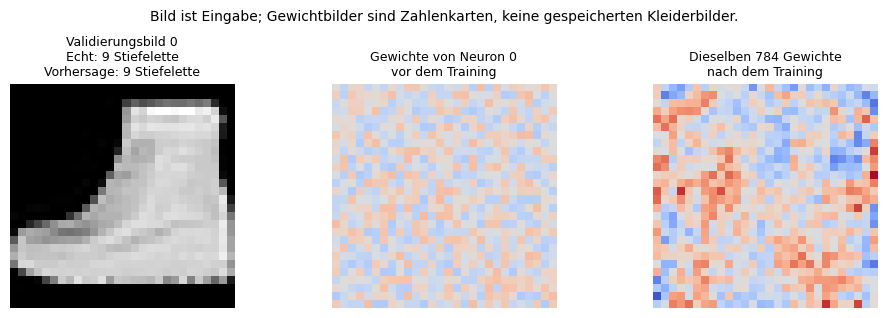

,Parameter,Loss Validierung,Treffer Validierung %,Echte Klasse Beispiel,Vorhergesagte Klasse Beispiel
0,101770,0.46,83.65,9,9


Gewichte und Bias-Werte tragen gemeinsam zum gelernten Verhalten bei.
Verstecktes Neuron 0 ist nicht die Ausgabeklasse 0.
Blau zeigt negative, Rot positive Gewichte; beide Zahlenkarten nutzen dieselbe Skala.


In [4]:
#@title E1 – Grundmodell trainieren und Gewichte anschauen { display-mode: "form" }
e1_table = run_e1()

## Runde 1 Störfall-Challenge bis Minute 20

**Bevor ihr E2 ausführt:** Jedes Mitglied nennt eine Vermutung: Was passiert bei 10 %, 30 % und 60 % beschädigten Verbindungsgewichten? Notiert eure gemeinsame Vorhersage kurz in der Labordokumentation.

Führt E2 aus. Der Code setzt ausgewählte Verbindungsgewichte in Kopien auf null. Die Grundwerte bleiben erhalten. Jede Stufe beginnt mit einer frischen Kopie des unbeschädigten Netzes; es wird nicht nachtrainiert.

1. Lest die **mittlere Trefferquote** bei 0 %, 10 %, 30 % und 60 % ab. Die Zusatzspalten zeigen die Spannweite aus drei Auswahlen.
2. Notiert eine Beobachtung mit zwei passenden Werten. Was war anders als erwartet?
3. Prüft kritisch: **Warum bedeutet verteiltes Wissen nicht, dass das Netz unzerstörbar ist?**

Hakt die Runde ab, wenn ihr eure Beobachtung belegt und erklärt habt, was das Ergebnis nicht beweist. Der Verlauf muss nicht bei jeder Stufe sinken. Auch eine widerlegte Vorhersage ist brauchbar. Die Prozentangabe betrifft Gewichte, nicht die Anzahl ausgefallener Neuronen.

Wechselt danach die Rollen. Das ursprüngliche Modell bleibt für die nächsten Runden unverändert.

Nur Verbindungsgewichte der beiden Linear-Schichten werden in Kopien auf null gesetzt.
Die Bias-Werte bleiben erhalten. Keine Kopie wird nachtrainiert.
Je Stufe drei feste Zufallsauswahlen; jede Stufe startet beim unbeschädigten Grundmodell.


,Gewichte ausgewählt %,Gewählte Gewichte,Treffer Mittelwert %,Treffer kleinster Wert %,Treffer grösster Wert %
0,0,0,83.65,83.65,83.65
1,10,10163,81.72,81.45,82.10
2,30,30489,73.80,68.50,78.50
3,60,60979,66.78,64.90,69.05


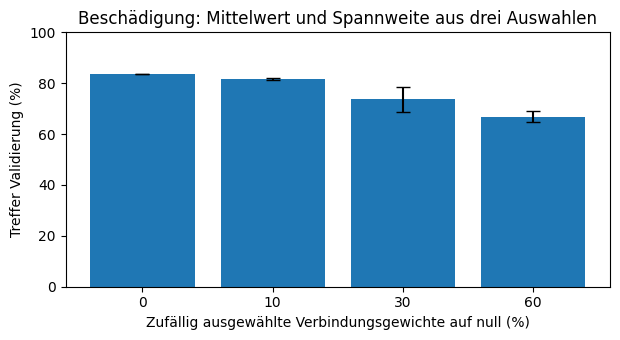

Grundmodell unverändert: ja. Einzelne Schwankungen sind möglich; Robustheit ist keine Garantie.


In [5]:
#@title E2 – Beschädigte Kopien vergleichen { display-mode: "form" }
e2_table = run_e2()

## Runde 2 Geheime Kleidungsbilder bis Minute 32

Das Colab wählt eine Zielklasse zufällig und verdeckt. Es sucht zwei künstliche Bilder für dieselbe Zielklasse. **Vor der Auflösung wird keine Zielklasse angezeigt.** Eine Rätselrunde genügt.

1. Führt **E3 Rätselbilder zeigen** aus. Betrachtet zwei Bildstarts, jeweils am Anfang, nach 50 und nach 300 Schritten.
2. Jedes Mitglied nennt eine Vermutung mit einem sichtbaren Merkmal. **«Nicht eindeutig erkennbar» ist erlaubt.** Notiert eure gemeinsame Vermutung vor der Auflösung.
3. Klickt erst jetzt auf **Zielklasse auflösen** unter den Bildern. Falls die Aufklappschaltfläche nicht funktioniert, führt die Ausweichzelle darunter aus.
4. Notiert eine Gemeinsamkeit und einen Unterschied der beiden Ergebnisse. Bei kaum sichtbaren Unterschieden schreibt ihr das ehrlich auf.
5. Prüft kritisch: **Was wurde verändert? Weshalb ist ein hoher Modellwert kein Beweis für ein natürliches Kleidungsfoto?**

Die Auflösung zeigt das Suchziel, keine objektiv richtige Klasse für ein echtes Foto. Während der Suche bleiben **Gewichte und Bias-Werte fest**. Nur die **Pixel** der künstlichen Startbilder ändern sich. Die 300 Schritte sind Bildänderungen, keine 300 Trainingsepochen. Das Ergebnis ist kein zurückgeholtes Erinnerungsfoto. Startbild und Glättung beeinflussen es ebenfalls.

Hakt die Runde ab, sobald ihr eure Beobachtung belegt und kritisch erklärt habt. Auch eine andere Vermutung als die Zielklasse ist zulässig. Wechselt danach die Rollen.

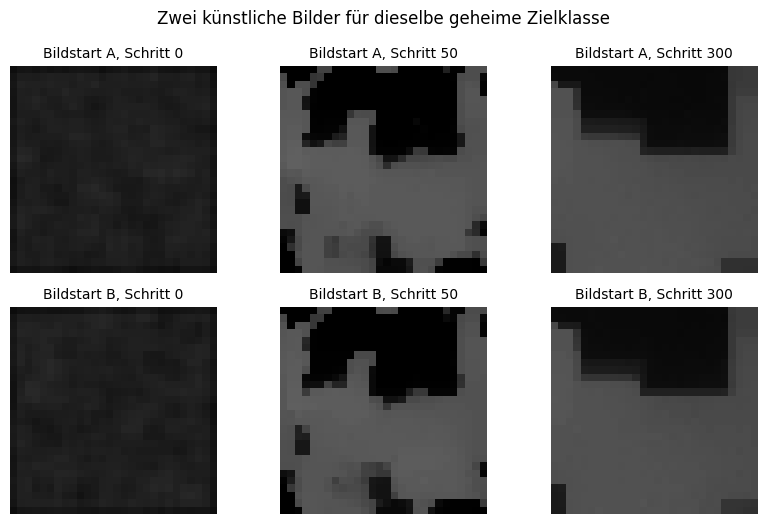

Notiert zuerst eure Vermutung und ein sichtbares Merkmal.
Auch 'nicht eindeutig erkennbar' ist eine gültige Beobachtung.
Klickt erst danach auf die geschlossene Aufklappschaltfläche.


In [6]:
#@title E3 Rätselbilder zeigen { display-mode: "form" }
run_mystery_game()

### Nur falls die Aufklappschaltfläche nicht funktioniert

Normalerweise genügt der Klick auf **Zielklasse auflösen** unter den Bildern. Führt die folgende Ausweichzelle nur aus, wenn der Klick nicht klappt und ihr eure Vermutung bereits notiert habt. Sie zeigt dieselbe Auflösung.

In [7]:
#@title Nur bei Bedarf nach eurer Vermutung Auflösung anzeigen { display-mode: "form" }
show_mystery_solution()

Gesuchtes Ziel: 8 Tasche
Bildstart A: Modellwert für das Ziel nach 300 Schritten 99.9 %
Bildstart B: Modellwert für das Ziel nach 300 Schritten 99.9 %
Die Zielklasse ist das Suchziel. Ein hoher Modellwert beweist kein natürliches Kleidungsfoto.
Die Pixel wurden verändert; Gewichte und Grundwerte blieben fest. Keine Erinnerungsfotos.


## Runde 3 Trainingsjury beginnt mit E4 bis Minute 38

Führt E4 aus. Ihr seht ein Originalbild sowie −10°, +10° und +45°.

Beurteilt im Team die vier Ansichten. Welche passen zu leicht schrägen Kleiderfotos? Wo könnten Teile am Rand fehlen oder untypische Ansichten entstehen?

Für das folgende Training werden nur **Original, −10° und +10°** benutzt. Die +45°-Ansicht dient der Diskussion. Die Bilder bleiben 28 × 28 Pixel gross; neue Randflächen werden schwarz. Drehen macht aus einem T-Shirt nicht automatisch eine andere Kleiderklasse.

Haltet in eurer Dokumentation kurz fest, welches Risiko eine grosse Drehung hat. Die kleinen Drehungen besprecht ihr im Team. Die Juryentscheidung folgt nach E5.

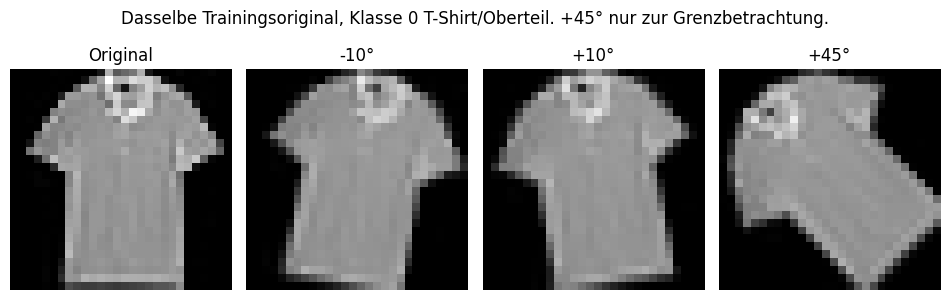

Aus einem Original entstehen Original, −10° und +10°: drei Trainingsansichten.
Aus 6'000 Originalen entstehen 18'000 Vorlagen, aber keine 18'000 unabhängigen Kleidungsstücke.
Die Klasse bleibt bei diesen kleinen Drehungen erhalten. Grosse Winkel können unpassend sein.
28 × 28 bleibt gleich; Randteile können bei der Drehung abgeschnitten werden.


In [8]:
#@title E4 – Original und Drehvarianten anschauen { display-mode: "form" }
rotation_example = run_e4()

## Runde 3 Trainingsjury mit E5 bis Minute 46

Verteilt zwei Beratungsrollen: **Auftrag A** braucht gute Ergebnisse auf geraden Bildern. **Auftrag B** erwartet häufig leicht schräge Bilder. Beide Seiten nutzen dieselbe Ergebnistabelle.

Führt E5 aus. Das Drehmodell startet frisch mit denselben Anfangswerten wie das Kontrollmodell. Es übernimmt keine Beschädigungen aus E2.

1. Übertragt die vier Trefferquoten in die Labordokumentation.
2. Empfehlt für Auftrag A und B jeweils ein Modell und begründet mit der passenden Spalte.
3. Prüft kritisch: **Warum ist der Trainingsaufwand fair? Weshalb sind 4'000 gedrehte Ansichten keine 4'000 unabhängig aufgenommenen Bilder?**

Beide Modelle haben dieselbe Netzform, Lernrate, Batchgrösse und Anzahl Vorlagenplätze. Beide verarbeiten 36'000 Bildpräsentationen in zwei Epochen. Beim Drehmodell unterscheiden sich zwei der drei Ansichten pro Original.

Geprüft wird auf **2'000 getrennten Validierungsoriginalen** und je einer −15°- und +15°-Ansicht davon. Das sind **4'000 abgeleitete Ansichten derselben Bilder**. Es ist eine Belastungsprüfung, kein unabhängiger Abschlusstest. Eine Verbesserung ist nicht garantiert.

Wenn ihr zwei Trefferquoten abzieht, lautet die Einheit **Prozentpunkte**. Von 70 % auf 75 % sind es +5 Prozentpunkte. Hakt die Runde ab, wenn ihr euer Urteil begründet und erklärt habt, was die Ergebnisse nicht beweisen. Wechselt danach die Rollen.

Vergleichsmodell mit −10° und +10°: 128 versteckte Neuronen, Lernrate 0.001, 2 Epochen
Gerät des Modells: cuda:0
Epoche 1: Validierungs-Loss 0.561; Treffer Validierung 79.70 %
Epoche 2: Validierungs-Loss 0.511; Treffer Validierung 82.05 %


,Training,Originale Validierung %,Gedrehte Validierung ±15° %,Bildpräsentationen,Anpassungsschritte
0,Ohne Drehung,83.65,52.30,36000,564
1,Mit Drehung ±10°,82.05,76.03,36000,564


Änderung auf Originalbildern: -1.60 Prozentpunkte
Änderung auf gedrehten Bildern: +23.73 Prozentpunkte
Gleiche Anfangswerte, Grundbilder, Vorlagenplätze, Reihenfolge, Lernrate, Epochen und Optimizer.
Nur zwei der drei Trainingsansichten pro Original unterscheiden sich.
Gedrehte Validierung: 4'000 Ansichten derselben 2'000 getrennten Bilder; kein unabhängiger Test.
Auch Gleichstand oder Verschlechterung ist ein gültiges Ergebnis.


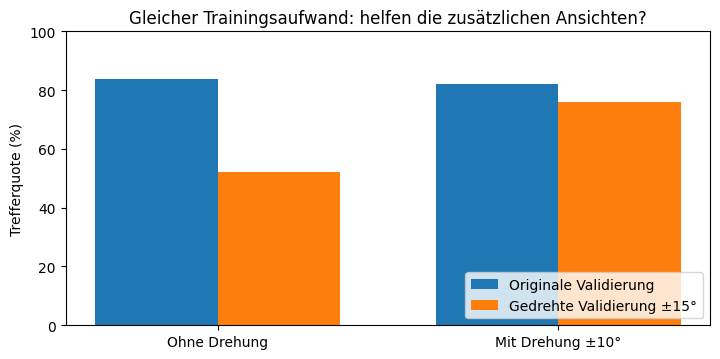

In [9]:
#@title E5 – Bei gleichem Trainingsaufwand vergleichen { display-mode: "form" }
e5_table = run_e5()

## Runde 4 Mythenjagd und Abgabe bis Minute 50

Repariert die drei verdächtigen Aussagen. Schreibt zu jeder Aussage einen kurzen richtigen Satz in die Labordokumentation:

1. «Einzelne Neuronen speichern Kleidungsfotos.»
2. «Unsere Bildsuche zeigt gespeicherte Erinnerungen.»
3. «Mehr Drehbilder machen das Netz immer besser.»

Drei Personen erklären je eine Korrektur. Eine vierte Person prüft die Belege. Zu dritt prüft ihr die Belege gemeinsam. Hakt die vierte Runde ab, wenn eure Sätze zu den Beobachtungen passen und die Grenzen der Versuche berücksichtigen.

Prüft eure gemeinsame Datei: Sind alle Namen, die Datenquelle, eure Beobachtungen und kritischen Prüfungen eingetragen und alle vier Spielrunden abgehakt? Noch leere Felder helfen euch, gezielt nachzudenken; ein gesetztes Zeichen ersetzt keine Erklärung.

Speichert **Colab15_Teamname.docx**. Eine Person lädt die gemeinsame Datei bis Ende der Arbeitszeit auf Moodle hoch. Das ist eure einzige Pflichtabgabe. Zusätzliche Trainingsläufe sind für dieses Spiel nicht nötig.

Copyright 2026 [Markus Ineichen](mailto:markus.ineichen1@sluz.ch)

Code licence: [MIT License](https://mit-license.org/)

Text license: [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)